# Customer Segmentation and Market Impact Strategy for Venture Creed

## Business Objective

The objective of this analysis is to segment Venture Creed's customer base based on customer characteristics and purchasing-related business attributes. The resulting clusters should be statistically meaningful, interpretable, and actionable from a marketing and sales perspective.

The final output aims to:

1. Identify distinct customer clusters.
2. Determine the optimal number of clusters.
3. Profile the characteristics of each cluster.
4. Detect data quality issues and potential outliers.
5. Assign actionable business strategies to each cluster.
6. Provide a robust framework to validate the final solution.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
!pip install kmodes -q
from kmodes.kmodes import KModes

## 1. Data Loading

The provided dataset is stored in Feather (.ftr) format. The first step is to load the dataset and validate its structure.

In [3]:
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_feather(filename)

print("Dataset Shape:", df.shape)
display(df.head())

Saving Clustering_Data.ftr to Clustering_Data (1).ftr
Dataset Shape: (3030, 18)


,Customer_ID,Street,City,State_Code,Postal_Code,Country,Seasonality_Segment,EA_Segment,Revenue_Bucket,Profit_Bucket,Market_Share_Segment,Casino_Size_Segment,Market_Potential_Segment,Churn_Segment,Competitiveness_Flag,Volume_Segment,Density_Segment,Propensity
0,Accoount 1,2295 BATTLEFORD RD,MISSISSAUGA,ON,L5N 2W8,CAN,None,None,None,None,None,None,None,None,Yes,High,High,-
1,Accoount 2,64 WESTBANK EXPY STE A,GRETNA,LA,70053,USA,None,None,None,None,None,None,None,None,-,Medium,Medium,-
2,Accoount 3,209-229 E Airline Hwy.,LaPlace,LA,70068,USA,None,None,None,None,None,None,None,None,-,Medium,Medium,-
3,Accoount 4,500 S MEADOWS PKWY,RENO,NV,89521,USA,None,None,None,None,None,None,None,None,Yes,High,High,-
4,Accoount 5,746 Victorian Avenue,Sparks,NV,89431,USA,None,None,None,None,None,None,None,None,Yes,High,High,-


In [4]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

Columns:
['Customer_ID', 'Street', 'City', 'State_Code', 'Postal_Code', 'Country', 'Seasonality_Segment', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Propensity']

Data Types:


,0
Customer_ID,object
Street,object
City,object
State_Code,object
Postal_Code,object
Country,object
Seasonality_Segment,object
EA_Segment,object
Revenue_Bucket,object
Profit_Bucket,object


## 2. Initial Data Audit and Quality Assessment

Before developing the clustering model, the dataset is evaluated for structural and data quality issues including missing values, duplicate records, duplicate customer identifiers, inconsistent data types, unexpected categories, and potential leakage from identifier fields.

In [5]:
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))

print("\nMissing Values:")
display(
    pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (df.isnull().mean() * 100).round(2)
    }).sort_values("Missing_Percentage", ascending=False)
)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDuplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

Total Rows: 3030
Total Columns: 18

Missing Values:


,Missing_Count,Missing_Percentage
Seasonality_Segment,748,24.69
Density_Segment,405,13.37
State_Code,308,10.17
EA_Segment,189,6.24
Street,1,0.03
Customer_ID,0,0.00
Country,0,0.00
Postal_Code,0,0.00
Revenue_Bucket,0,0.00
City,0,0.00



Duplicate Rows: 0

Duplicate Customer IDs: 0


In [6]:
quality_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (df.isnull().mean() * 100).round(2).values,
    "Unique_Values": df.nunique().values
})

display(quality_summary)

,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,Customer_ID,object,0,0.00,3030
1,Street,object,1,0.03,2461
2,City,object,0,0.00,1245
3,State_Code,object,308,10.17,60
4,Postal_Code,object,0,0.00,1124
5,Country,object,0,0.00,33
6,Seasonality_Segment,object,748,24.69,4
7,EA_Segment,object,189,6.24,4
8,Revenue_Bucket,object,0,0.00,4
9,Profit_Bucket,object,0,0.00,4


## 3. Feature Categorization

The variables are categorized based on their analytical purpose. Identifier and highly granular address fields are separated from business segmentation variables to avoid creating artificial clusters.

In [7]:
identifier_features = [
    "Customer_ID"
]

address_features = [
    "Street",
    "City",
    "State_Code",
    "Postal_Code",
    "Country"
]

business_features = [
    "Seasonality_Segment",
    "EA_Segment",
    "Revenue_Bucket",
    "Profit_Bucket",
    "Market_Share_Segment",
    "Casino_Size_Segment",
    "Market_Potential_Segment",
    "Churn_Segment",
    "Competitiveness_Flag",
    "Volume_Segment",
    "Density_Segment",
    "Propensity"
]

print("Identifier Features:", identifier_features)
print("Address Features:", address_features)
print("Business Features:", business_features)

Identifier Features: ['Customer_ID']
Address Features: ['Street', 'City', 'State_Code', 'Postal_Code', 'Country']
Business Features: ['Seasonality_Segment', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Propensity']


### EDA-Exploratory Data Analysis

Next step is to perform EDA on dataset to understand the data for performing clustering


In [8]:
for col in business_features:
    print(f"\n{'='*60}")
    print(col)
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="Customer_Count")
    )


Seasonality_Segment


,Seasonality_Segment,Customer_Count
0,None,1579
1,None,748
2,Potentially Seasonal,455
3,Highly Seasonal,142
4,Non Seasonal,106



EA_Segment


,EA_Segment,Customer_Count
0,None,2356
1,Early Adopter,285
2,None,189
3,Late Adopter,107
4,Trend Follower,93



Revenue_Bucket


...

,Volume_Segment,Customer_Count
0,High,1304
1,-,623
2,Medium,605
3,Low,498



Density_Segment


,Density_Segment,Customer_Count
0,High,1368
1,-,623
2,Medium,477
3,None,405
4,Low,157



Propensity


,Propensity,Customer_Count
0,-,2071
1,M,653
2,H,158
3,L,148


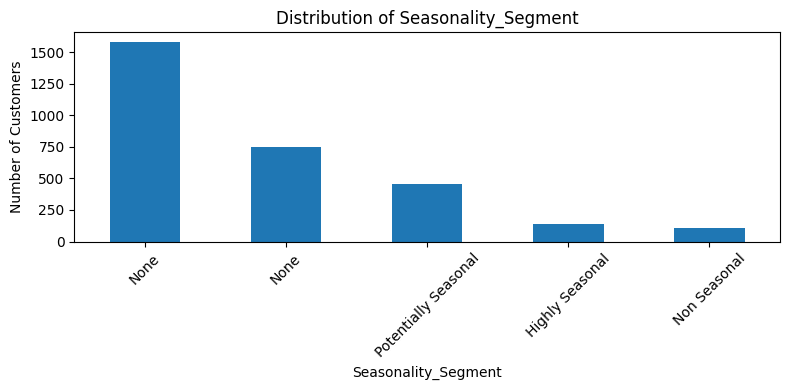

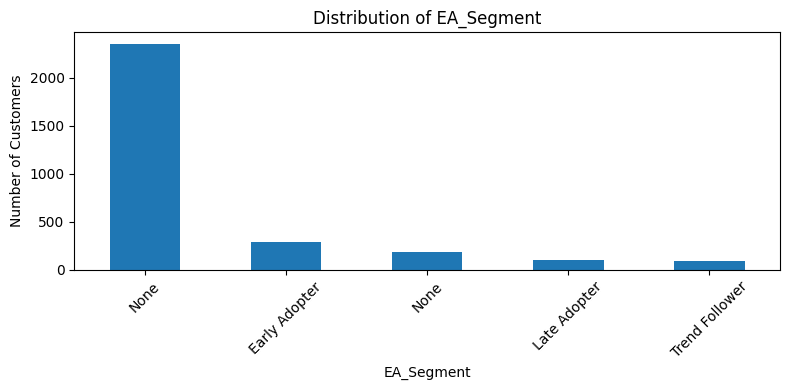

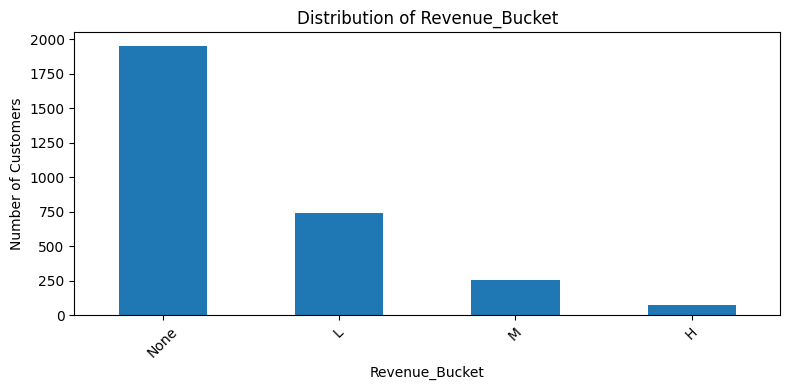

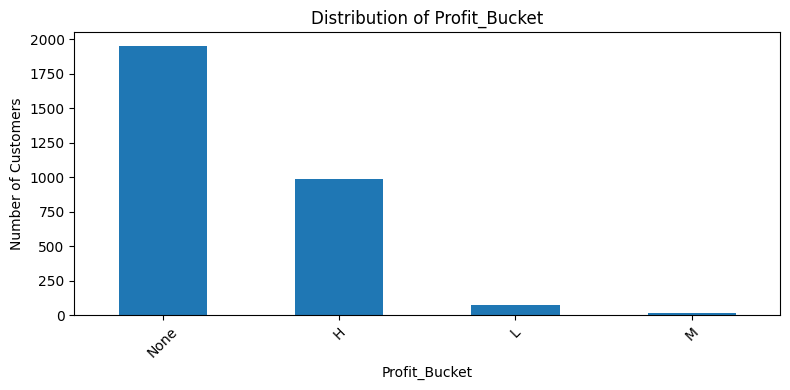

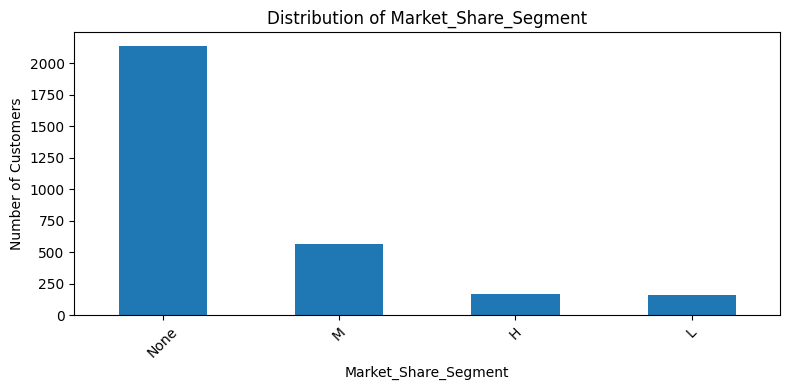

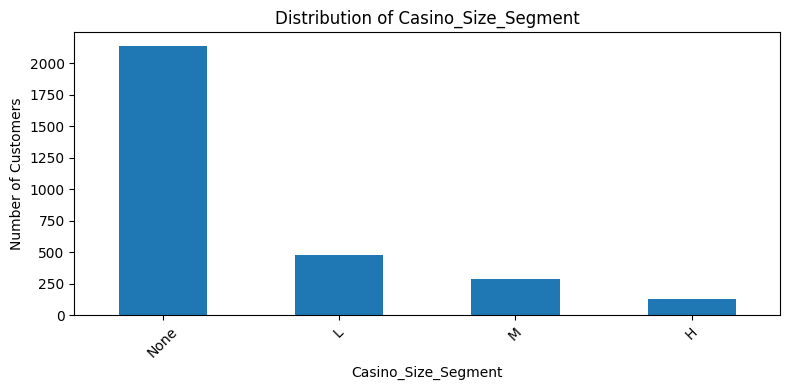

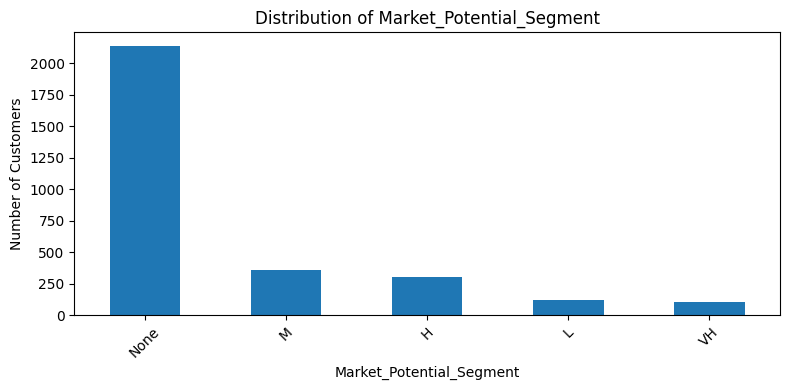

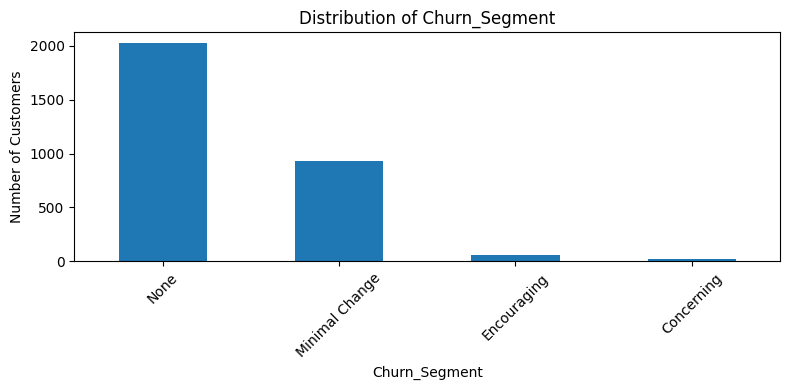

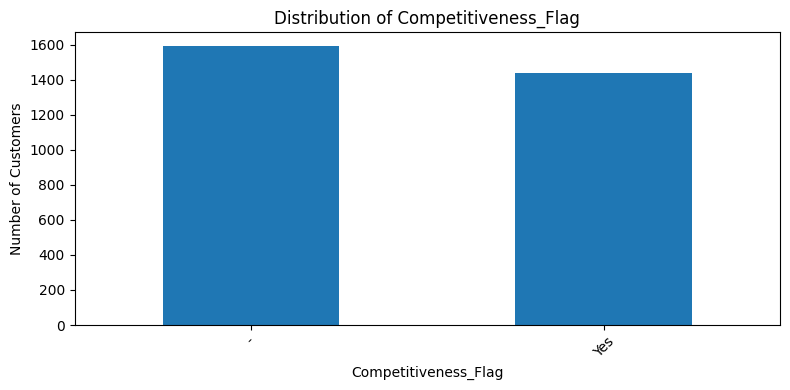

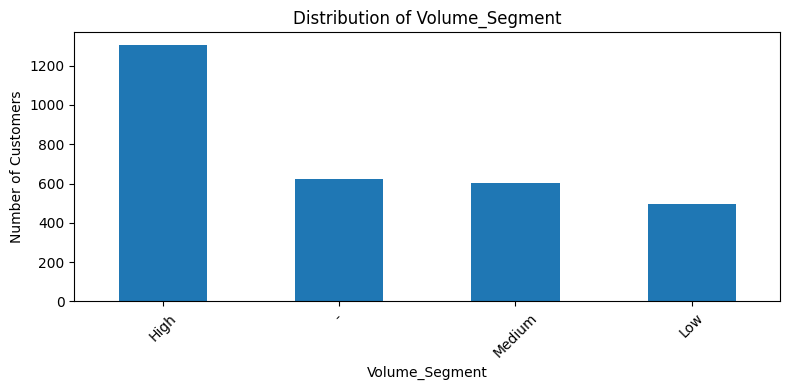

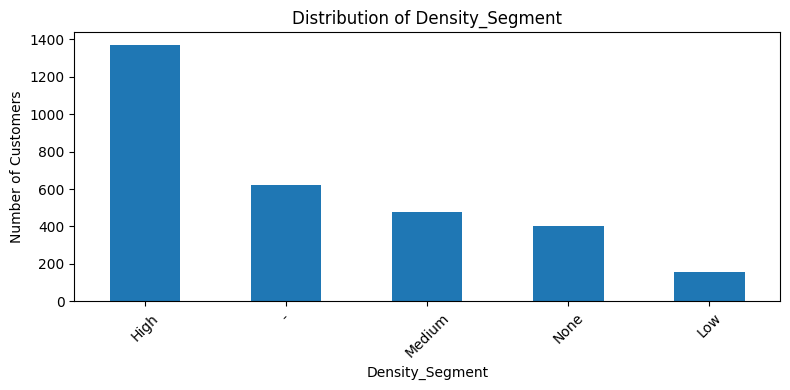

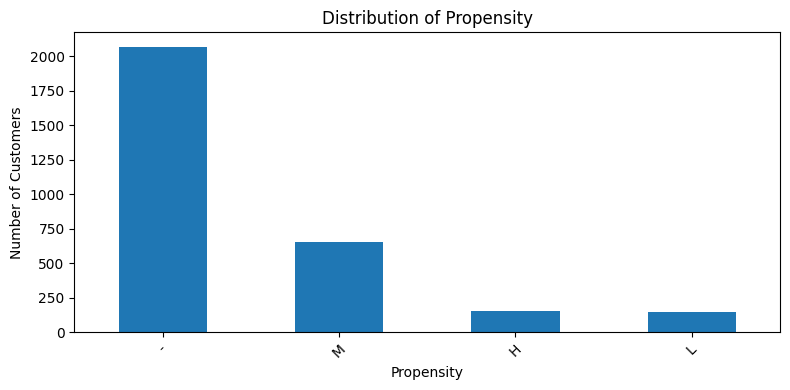

In [9]:
for col in business_features:
    plt.figure(figsize=(8, 4))

    df[col].value_counts(dropna=False).plot(kind="bar")

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### EDA Summary

The exploratory data analysis was performed to understand the distribution of customers across the provided business segmentation variables.

The analysis includes:

- Category-wise customer distribution for each business feature.
- Comparison of the relative frequency of different customer segments.
- Identification of features with limited variation or highly concentrated categories.
- Identification of potentially rare categories for further data-quality review.

The EDA results will be used in subsequent steps for feature selection, redundancy analysis, outlier detection, and clustering. No feature is removed solely based on its distribution; statistical redundancy and business relevance will also be considered.

# 4. Data Quality Assessment

Data quality is critical before clustering because incorrect, inconsistent, or redundant input features can lead to misleading customer segments.

The dataset will be evaluated for:

1. Missing values
2. Duplicate records
3. Duplicate Customer IDs
4. Inconsistent category formatting
5. Leading/trailing whitespace

In [10]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()

for col in categorical_cols:
    original_unique = df[col].nunique(dropna=False)

    cleaned_unique = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .nunique(dropna=False)
    )

    print(f"{col}: Original unique values = {original_unique}, "
          f"After standardization = {cleaned_unique}")

Customer_ID: Original unique values = 3030, After standardization = 3030
Street: Original unique values = 2462, After standardization = 2388
City: Original unique values = 1245, After standardization = 1014
State_Code: Original unique values = 61, After standardization = 61
Postal_Code: Original unique values = 1124, After standardization = 1124
Country: Original unique values = 33, After standardization = 33
Seasonality_Segment: Original unique values = 5, After standardization = 4
EA_Segment: Original unique values = 5, After standardization = 4
Revenue_Bucket: Original unique values = 4, After standardization = 4
Profit_Bucket: Original unique values = 4, After standardization = 4
Market_Share_Segment: Original unique values = 4, After standardization = 4
Casino_Size_Segment: Original unique values = 4, After standardization = 4
Market_Potential_Segment: Original unique values = 5, After standardization = 5
Churn_Segment: Original unique values = 4, After standardization = 4
Competi

### Observation

Formatting inconsistencies were identified in Street, City, Seasonality_Segment, and EA_Segment. These fields will be standardized before further analysis.


In [11]:
# Create a cleaned copy of the dataset
df_clean = df.copy()

# Standardize all categorical text columns
for col in categorical_cols:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

print("Category standardization completed.")

Category standardization completed.


In [14]:
missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (df_clean.isnull().mean() * 100).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)
duplicate_summary = {
    "Duplicate Rows": df_clean.duplicated().sum(),
    "Duplicate Customer IDs": df_clean["Customer_ID"].duplicated().sum(),
    "Total Customers": len(df_clean)
}

display(pd.DataFrame(
    duplicate_summary.items(),
    columns=["Quality Check", "Count"]
))

,Missing_Count,Missing_Percentage
Customer_ID,0,0.0
Street,0,0.0
City,0,0.0
State_Code,0,0.0
Postal_Code,0,0.0
Country,0,0.0
Seasonality_Segment,0,0.0
EA_Segment,0,0.0
Revenue_Bucket,0,0.0
Profit_Bucket,0,0.0


,Quality Check,Count
0,Duplicate Rows,0
1,Duplicate Customer IDs,0
2,Total Customers,3030


### Observation

The dataset contains 3,030 customer records with no duplicate rows and no duplicate Customer IDs. Therefore, no duplicate-record removal is required before clustering.

## 5. Constant and Low-Variability Feature Checks

Features with only one unique value cannot differentiate customers and therefore provide no value for clustering. Such features are identified and excluded from the model input.

In [15]:
feature_variability = pd.DataFrame({
    "Feature": df_clean.columns,
    "Unique_Values": [df_clean[col].nunique() for col in df_clean.columns],
    "Unique_Percentage": [
        round((df_clean[col].nunique() / len(df_clean)) * 100, 2)
        for col in df_clean.columns
    ]
})

display(feature_variability.sort_values("Unique_Values"))

,Feature,Unique_Values,Unique_Percentage
14,Competitiveness_Flag,2,0.07
6,Seasonality_Segment,4,0.13
13,Churn_Segment,4,0.13
7,EA_Segment,4,0.13
9,Profit_Bucket,4,0.13
10,Market_Share_Segment,4,0.13
8,Revenue_Bucket,4,0.13
11,Casino_Size_Segment,4,0.13
15,Volume_Segment,4,0.13
17,Propensity,4,0.13


### Observation

No constant features were identified in the dataset. All business segmentation variables contain multiple categories and therefore have the potential to differentiate customers during clustering.

However, high-cardinality fields such as Street, Postal_Code, and City will be evaluated separately because a large number of unique values can create overly granular and potentially non-actionable customer groupings.

# 6. Feature Selection

The objective of feature selection is to retain variables that represent meaningful customer behavior and business characteristics while excluding identifiers, highly granular address fields, and potentially redundant information.

The feature selection approach is based on:

1. Identifier relevance
2. Cardinality
3. Statistical redundancy
4. Business interpretability
5. Actionability for marketing and sales strategy

In [16]:
identifier_features = [
    "Customer_ID"
]

high_cardinality_address_features = [
    "Street",
    "City",
    "Postal_Code"
]

geographic_features = [
    "State_Code",
    "Country"
]

business_features = [
    "Seasonality_Segment",
    "EA_Segment",
    "Revenue_Bucket",
    "Profit_Bucket",
    "Market_Share_Segment",
    "Casino_Size_Segment",
    "Market_Potential_Segment",
    "Churn_Segment",
    "Competitiveness_Flag",
    "Volume_Segment",
    "Density_Segment",
    "Propensity"
]

print("Identifier Features:")
print(identifier_features)

print("\nHigh-Cardinality Address Features:")
print(high_cardinality_address_features)

print("\nGeographic Features:")
print(geographic_features)

print("\nBusiness Features:")
print(business_features)

Identifier Features:
['Customer_ID']

High-Cardinality Address Features:
['Street', 'City', 'Postal_Code']

Geographic Features:
['State_Code', 'Country']

Business Features:
['Seasonality_Segment', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Propensity']


In [18]:
final_features = business_features.copy()

X = df_clean[final_features].copy()

print("Final features selected for clustering:")
print(final_features)

print("\nModel input shape:", X.shape)

Final features selected for clustering:
['Seasonality_Segment', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Propensity']

Model input shape: (3030, 12)


# 7. Outlier Detection

Traditional numerical outlier detection methods such as Z-score and IQR are not directly applicable to the selected categorical customer segmentation variables.

Therefore, potential anomalies are assessed using:

1. Rare category detection to identify unusually infrequent customer characteristics.
2. Multivariate anomaly detection after encoding the categorical features.

Detected anomalies are flagged for review rather than automatically removed, as an unusual customer profile may represent a genuine and strategically important customer.

In [19]:
rare_category_summary = []

for col in final_features:

    proportions = (
        df_clean[col]
        .value_counts(normalize=True, dropna=False)
    )

    rare_categories = proportions[proportions < 0.01]

    for category, proportion in rare_categories.items():
        rare_category_summary.append({
            "Feature": col,
            "Category": category,
            "Customer_Percentage": round(proportion * 100, 2)
        })

rare_category_df = pd.DataFrame(rare_category_summary)

if rare_category_df.empty:
    print("No categories with less than 1% customer representation were identified.")
else:
    display(rare_category_df)

,Feature,Category,Customer_Percentage
0,Profit_Bucket,m,0.63
1,Churn_Segment,concerning,0.79


In [20]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import IsolationForest

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_encoded = encoder.fit_transform(X)

iso_forest = IsolationForest(
    contamination=0.03,
    random_state=42
)

outlier_labels = iso_forest.fit_predict(X_encoded)

df_clean["Outlier_Flag"] = np.where(
    outlier_labels == -1,
    "Potential Outlier",
    "Normal"
)

df_clean["Outlier_Flag"].value_counts()

,count
Outlier_Flag,
Normal,2939
Potential Outlier,91


### Multivariate Outlier Detection Results

Isolation Forest was applied to the encoded business features to identify unusual combinations of customer characteristics.

Out of 3,030 customers:

- 2,939 customers (97.0%) were classified as normal.
- 91 customers (3.0%) were flagged as potential outliers.

The flagged customers are retained in the dataset because unusual customer profiles may represent genuine and strategically important accounts rather than data errors. The outlier flag is used for analysis and validation and is not included as an input feature for customer clustering.

# 8. Clustering Data Preparation

The final clustering dataset consists of the selected business segmentation features.

The features are categorical in nature; therefore, the data is prepared as categorical values for use with K-Modes clustering. K-Modes is selected because it is designed for categorical data and avoids imposing artificial numerical distances between category labels.

In [21]:
X_cluster = df_clean[final_features].copy()

# Ensure all clustering features are treated as categorical
X_cluster = X_cluster.astype(str)

print("Clustering input shape:", X_cluster.shape)
print("\nFeatures used for clustering:")
print(X_cluster.columns.tolist())

Clustering input shape: (3030, 12)

Features used for clustering:
['Seasonality_Segment', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Propensity']


# 9. Determining the Optimal Number of Clusters

As customer segmentation is an unsupervised learning problem, the number of clusters is not predefined.

K-Modes clustering is evaluated for multiple values of K. The optimal number of clusters will be selected based on:

1. Reduction in clustering cost.
2. The elbow point in the cost curve.
3. Reasonable distribution of customers across clusters.
4. Business interpretability and actionability of the resulting segments.

In [22]:
from kmodes.kmodes import KModes

cluster_results = []

for k in range(2, 9):

    km = KModes(
        n_clusters=k,
        init="Huang",
        n_init=20,
        random_state=42
    )

    labels = km.fit_predict(X_cluster)

    cluster_results.append({
        "Number_of_Clusters": k,
        "Clustering_Cost": km.cost_
    })

results_df = pd.DataFrame(cluster_results)

display(results_df)

,Number_of_Clusters,Clustering_Cost
0,2,9021.0
1,3,7093.0
2,4,6404.0
3,5,5906.0
4,6,5515.0
5,7,5147.0
6,8,4924.0


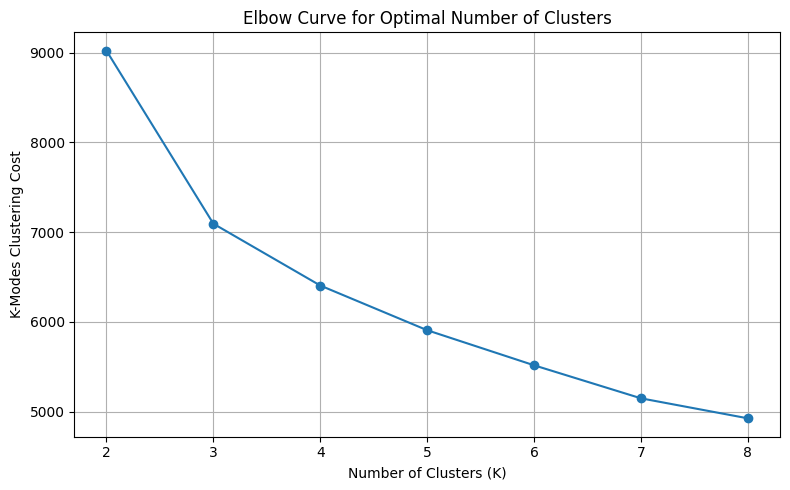

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Number_of_Clusters"],
    results_df["Clustering_Cost"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("K-Modes Clustering Cost")
plt.title("Elbow Curve for Optimal Number of Clusters")

plt.xticks(range(2, 9))
plt.grid(True)

plt.tight_layout()
plt.show()

### Selection of Optimal Number of Clusters

The K-Modes cost curve shows a substantial reduction in clustering cost as the number of clusters increases from 2 to 5. Beyond K=5, the reduction becomes more gradual, indicating diminishing returns from adding additional clusters.

Therefore, **K=5** is selected as the optimal number of customer clusters. This choice provides a balance between segmentation granularity, model complexity, and business interpretability. The resulting clusters will be further validated based on their size, characteristics, and actionability.

In [25]:
optimal_k = 5

final_kmodes = KModes(
    n_clusters=optimal_k,
    init="Huang",
    n_init=50,
    random_state=42
)

df_clean["Cluster"] = final_kmodes.fit_predict(X_cluster)

cluster_counts = (
    df_clean["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_percentages = (
    df_clean["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

cluster_summary = pd.DataFrame({
    "Customer_Count": cluster_counts,
    "Customer_Percentage": cluster_percentages
})

display(cluster_summary)

,Customer_Count,Customer_Percentage
Cluster,,
0,1128,37.23
1,454,14.98
2,288,9.50
3,848,27.99
4,312,10.30


### Cluster Size Validation

The five clusters have meaningful customer representation, with cluster sizes ranging from 9.50% to 37.23% of the customer base.

No cluster is empty or contains an extremely small number of customers. Therefore, the selected K=5 solution provides sufficiently large and actionable customer segments for further business profiling.

# 10. Cluster Profiling

Each cluster is profiled using the distribution of the selected business features. This analysis is used to identify the dominant characteristics of each customer segment and translate the clusters into meaningful business strategies.

In [26]:
for col in final_features:

    print(f"\n{'='*70}")
    print(f"Feature: {col}")

    profile = pd.crosstab(
        df_clean["Cluster"],
        df_clean[col],
        normalize="index"
    ) * 100

    display(profile.round(2))


Feature: Seasonality_Segment


Seasonality_Segment,highly seasonal,non seasonal,none,potentially seasonal
Cluster,,,,
0,0.35,0.35,96.81,2.48
1,13.00,7.49,32.82,46.70
2,5.56,4.51,73.61,16.32
3,0.12,0.12,99.29,0.47
4,19.87,17.31,10.26,52.56



Feature: EA_Segment


EA_Segment,early adopter,late adopter,none,trend follower
Cluster,,,,
0,1.15,0.80,97.52,0.53
1,15.42,10.79,66.08,7.71
2,9.03,3.82,82.99,4.17
3,0.47,0.24,99.17,0.12
4,55.13,11.54,20.83,12.50



Feature: Revenue_Bucket


...

Volume_Segment,-,high,low,medium
Cluster,,,,
0,55.23,3.19,19.41,22.16
1,0.00,25.99,40.97,33.04
2,0.00,73.96,6.94,19.10
3,0.00,87.38,4.01,8.61
4,0.00,62.82,12.50,24.68



Feature: Density_Segment


Density_Segment,-,high,low,medium,none
Cluster,,,,,
0,55.23,15.69,1.77,14.10,13.21
1,0.00,41.85,3.52,27.75,26.87
2,0.00,75.35,3.12,14.58,6.94
3,0.00,76.53,6.60,11.67,5.19
4,0.00,43.27,17.95,16.35,22.44



Feature: Propensity


Propensity,-,h,l,m
Cluster,,,,
0,90.69,0.00,6.21,3.10
1,16.96,3.74,4.41,74.89
2,60.42,4.86,9.38,25.35
3,93.75,0.00,3.30,2.95
4,0.64,40.71,0.96,57.69


In [27]:
cluster_profiles = []

for cluster in sorted(df_clean["Cluster"].unique()):

    cluster_data = df_clean[df_clean["Cluster"] == cluster]

    profile = {"Cluster": cluster}

    for feature in final_features:

        dominant_category = cluster_data[feature].mode()[0]

        dominant_percentage = (
            (cluster_data[feature] == dominant_category).mean() * 100
        )

        profile[feature] = (
            f"{dominant_category} "
            f"({dominant_percentage:.1f}%)"
        )

    cluster_profiles.append(profile)

cluster_profile_summary = pd.DataFrame(cluster_profiles)

display(cluster_profile_summary)

,Cluster,Seasonality_Segment,EA_Segment,Revenue_Bucket,Profit_Bucket,Market_Share_Segment,Casino_Size_Segment,Market_Potential_Segment,Churn_Segment,Competitiveness_Flag,Volume_Segment,Density_Segment,Propensity
0,0,none (96.8%),none (97.5%),none (97.5%),none (97.5%),none (93.8%),none (93.8%),none (93.8%),none (95.2%),- (100.0%),- (55.2%),- (55.2%),- (90.7%)
1,1,potentially seasonal (46.7%),none (66.1%),l (84.1%),h (92.3%),m (62.1%),l (79.3%),m (58.8%),minimal change (90.5%),- (63.7%),low (41.0%),high (41.9%),m (74.9%)
2,2,none (73.6%),none (83.0%),l (91.3%),h (86.5%),none (87.8%),none (87.8%),none (87.8%),minimal change (63.9%),yes (76.4%),high (74.0%),high (75.3%),- (60.4%)
3,3,none (99.3%),none (99.2%),none (100.0%),none (100.0%),none (94.6%),none (94.6%),none (94.6%),none (98.6%),yes (96.8%),high (87.4%),high (76.5%),- (93.8%)
4,4,potentially seasonal (52.6%),early adopter (55.1%),m (59.6%),h (98.1%),m (72.4%),m (66.7%),h (71.8%),minimal change (89.7%),yes (74.7%),high (62.8%),high (43.3%),m (57.7%)


In [28]:
cluster_names = {
    0: "Dormant Low-Activity Accounts",
    1: "Profitable Developing Accounts",
    2: "Competitive White-Space Accounts",
    3: "Dormant Competitive Accounts",
    4: "High-Potential Early-Adopter Accounts"
}

df_clean["Cluster_Name"] = df_clean["Cluster"].map(cluster_names)

display(
    df_clean[
        ["Customer_ID", "Cluster", "Cluster_Name"]
    ].head()
)

,Customer_ID,Cluster,Cluster_Name
0,accoount 1,3,Dormant Competitive Accounts
1,accoount 2,0,Dormant Low-Activity Accounts
2,accoount 3,0,Dormant Low-Activity Accounts
3,accoount 4,3,Dormant Competitive Accounts
4,accoount 5,3,Dormant Competitive Accounts


# 11. Cluster-Based Business Strategy

The final customer clusters are translated into actionable business segments. Each cluster is assigned a recommended marketing and sales strategy based on its dominant customer characteristics, growth potential, profitability, and competitive environment.

In [29]:
strategy_mapping = pd.DataFrame({
    "Cluster": [0, 1, 2, 3, 4],

    "Cluster_Name": [
        "Dormant Low-Activity Accounts",
        "Profitable Developing Accounts",
        "Competitive White-Space Accounts",
        "Dormant Competitive Accounts",
        "High-Potential Early-Adopter Accounts"
    ],

    "Recommended_Strategy": [
        "Low-cost reactivation campaigns and targeted outreach. Avoid high marketing spend until purchase potential is validated.",

        "Strengthen relationships through loyalty benefits, cross-selling, and account development to increase revenue while protecting profitability.",

        "Prioritize targeted sales outreach to understand barriers to market penetration. Use competitive offers and account-specific engagement.",

        "Use selective and cost-efficient engagement. Focus sales effort on accounts showing signals of reactivation rather than broad marketing spend.",

        "Prioritize for growth investment, early-access programs, premium offers, and dedicated account management due to strong potential and early-adopter behavior."
    ]
})

display(strategy_mapping)

,Cluster,Cluster_Name,Recommended_Strategy
0,0,Dormant Low-Activity Accounts,Low-cost reactivation campaigns and targeted o...
1,1,Profitable Developing Accounts,Strengthen relationships through loyalty benef...
2,2,Competitive White-Space Accounts,Prioritize targeted sales outreach to understa...
3,3,Dormant Competitive Accounts,Use selective and cost-efficient engagement. F...
4,4,High-Potential Early-Adopter Accounts,"Prioritize for growth investment, early-access..."


# 12. 2-D Visualization of Customer Clusters

The clustering model uses multiple categorical business features. To visualize the resulting customer segments, the encoded feature space is reduced to two dimensions using Principal Component Analysis (PCA).

The 2-D plot is used for visual interpretation of the cluster structure. The original K-Modes clustering results remain the basis for the final customer segmentation.

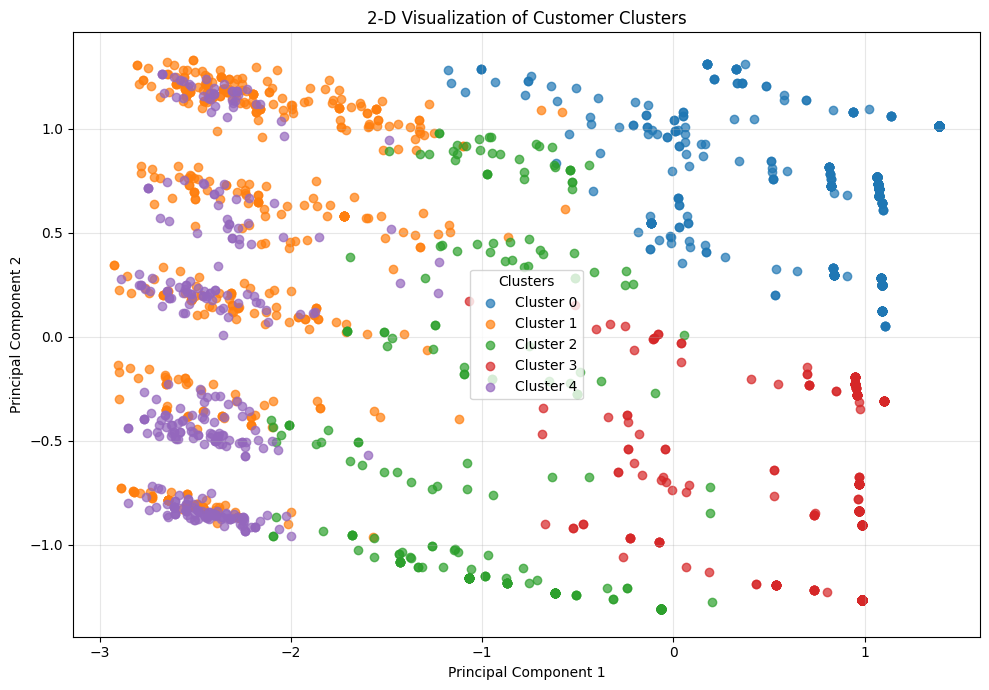

In [30]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce encoded customer features to two dimensions
pca = PCA(n_components=2, random_state=42)

X_2d = pca.fit_transform(X_encoded)

# Create visualization
plt.figure(figsize=(10, 7))

for cluster in sorted(df_clean["Cluster"].unique()):

    mask = df_clean["Cluster"] == cluster

    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2-D Visualization of Customer Clusters")
plt.legend(title="Clusters")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
validation_summary = pd.DataFrame({
    "Validation_Check": [
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Customer IDs",
        "Constant Features",
        "Cluster Count",
        "Empty Clusters",
        "Smallest Cluster Size",
        "Largest Cluster Size"
    ],

    "Result": [
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean["Customer_ID"].duplicated().sum(),
        sum(df_clean[col].nunique() == 1 for col in final_features),
        df_clean["Cluster"].nunique(),
        sum(df_clean["Cluster"].value_counts() == 0),
        df_clean["Cluster"].value_counts().min(),
        df_clean["Cluster"].value_counts().max()
    ]
})

display(validation_summary)

,Validation_Check,Result
0,Missing Values,0
1,Duplicate Rows,0
2,Duplicate Customer IDs,0
3,Constant Features,0
4,Cluster Count,5
5,Empty Clusters,0
6,Smallest Cluster Size,288
7,Largest Cluster Size,1128


### Validation Summary

The final solution was validated using the following checks:

1. No missing values were identified.
2. No duplicate customer records or duplicate Customer IDs were identified.
3. No constant clustering features were present.
4. All five clusters contain meaningful numbers of customers.
5. The smallest cluster contains a sufficient number of customers for business analysis.
6. Rare categories and multivariate outliers were identified but retained because unusual customer profiles may represent genuine business opportunities.
7. The selected clusters show distinct business characteristics and can be linked to differentiated marketing and sales strategies.

These checks support the reliability and business usability of the final customer segmentation solution.

In [33]:
final_output = df_clean[
    ["Customer_ID", "Cluster", "Cluster_Name"]
].copy()

display(final_output.head(10))

,Customer_ID,Cluster,Cluster_Name
0,accoount 1,3,Dormant Competitive Accounts
1,accoount 2,0,Dormant Low-Activity Accounts
2,accoount 3,0,Dormant Low-Activity Accounts
3,accoount 4,3,Dormant Competitive Accounts
4,accoount 5,3,Dormant Competitive Accounts
5,accoount 6,3,Dormant Competitive Accounts
6,accoount 7,0,Dormant Low-Activity Accounts
7,accoount 8,0,Dormant Low-Activity Accounts
8,accoount 9,3,Dormant Competitive Accounts
9,accoount 10,1,Profitable Developing Accounts


# 13. Conclusion

A K-Modes clustering approach was developed to segment 3,030 customers based on 12 business-related categorical features.

Five customer clusters were selected using the K-Modes cost curve, cluster size validation, and business interpretability. The resulting segments demonstrate distinct characteristics related to revenue, profitability, market potential, customer adoption behavior, competitiveness, and purchasing propensity.

The final segmentation provides an actionable framework for differentiated marketing and sales strategies, enabling Venture Creed to prioritize high-potential accounts, develop profitable customers, selectively reactivate dormant accounts, and improve penetration in competitive markets.